# imports

In [2]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from astropy.io import fits
import astropy.units as u
import astropy.constants as c

from matplotlib.patches import Circle
from astrodendro import Dendrogram

from scipy import ndimage

In [3]:
def first_moment(array,sum_axis):
    num = np.nansum(array*sum_axis[:,np.newaxis,np.newaxis],axis=0)
    den = np.nansum(array,axis=0)
    
    return num/den


def second_moment(array,sum_axis):
    m1 = first_moment(array,sum_axis)
    
    
    num = np.nansum(array*(sum_axis[:,np.newaxis,np.newaxis]-m1[np.newaxis,:])**2,axis=0)
    den = np.nansum(array,axis=0)
    
    return np.sqrt(num/den)


In [4]:
m33_120pc = fits.open('../data/m33_C+D+tp_himidres_120pc.fits')[0].data[60:180] # just choosing velocities between -53 and -300 km/s

header = fits.open('../data/m33_C+D+tp_himidres_120pc.fits')[0].header

rax,dax,vax = [(np.arange(header[f'NAXIS{n}'])-header[f'CRPIX{n}'])*header[f'CDELT{n}'] + header[f'CRVAL{n}'] for n in [1,2,3]]
vax = (vax/1e3)[60:180]

In [5]:
m0 = np.nansum(m33_120pc*2.061,axis=0)#*u.K*u.km/u.s
m0_lv = np.nansum(m33_120pc,axis=1)
m0_bv = np.nansum(m33_120pc,axis=2)


m1 = first_moment(m33_120pc,vax)
m2 = second_moment(m33_120pc,vax)

/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_83490/3168341644.py:5: RuntimeWarning: invalid value encountered in divide
  return num/den
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_83490/3168341644.py:15: RuntimeWarning: invalid value encountered in divide
  return np.sqrt(num/den)
/var/folders/wv/y9bnhr2x4q98_z1q32p4kwtm0000gn/T/ipykernel_83490/3168341644.py:15: RuntimeWarning: invalid value encountered in sqrt
  return np.sqrt(num/den)


In [6]:
def rotate_cube(cube, axis, angle, order=1, reshape=False, cval=np.nan):
    """Rotate a 3D array by `angle` degrees in the plane orthogonal to `axis`.

    axis   : rotation axis, 0/1/2 (held fixed; the other two turn into
             each other). For a (v, dec, ra) cube, axis=0 is a
             position-angle rotation of the sky plane at fixed velocity.
    angle  : degrees; positive turns the first remaining axis toward the
             second (axis=0 -> dec rotates toward ra).
    order  : spline order. 1 (bilinear) avoids the ringing and negative
             overshoot that order>1 produces at sharp edges; 0 is
             nearest-neighbour, exact but blocky.
    reshape: False keeps the original shape and lets corners rotate out of
             frame; True grows the array so nothing is clipped.
    cval   : fill for pixels rotated in from outside the data (default NaN,
             so np.nansum just skips them).
    """
    cube = np.asarray(cube)
    if cube.ndim != 3:
        raise ValueError(f"expected a 3D array, got shape {cube.shape}")

    axis = int(axis) % 3
    plane = tuple(a for a in range(3) if a != axis)

    dtype = cube.dtype if cube.dtype.kind == "f" else np.float64
    work = cube.astype(dtype, copy=False)

    kw = dict(axes=plane, reshape=reshape, order=order,
              mode="constant", prefilter=order > 1)

    # Rotate the data with blanks zeroed, and rotate a validity mask
    # alongside it. Dividing by the rotated mask undoes the dilution those
    # zeros cause at the edges, and the mask marks output pixels with no
    # real data behind them.
    bad = ~np.isfinite(work)
    filled = np.where(bad, 0, work) if bad.any() else work

    out = ndimage.rotate(filled, angle, cval=0, **kw)
    wgt = ndimage.rotate((~bad).astype(dtype), angle, cval=0, **kw)

    with np.errstate(invalid="ignore", divide="ignore"):
        out /= wgt
    out[wgt < 0.5] = cval

    return out


In [ ]:
m33_highres = fits.open('/Volumes/imara-lab/M33/HI/M33_A+B+C+D_HI_0p4kms_feathered_K_reimaged.fits')[0].data

In [7]:
rotated = rotate_cube(m33_120pc,axis=2,angle=5)

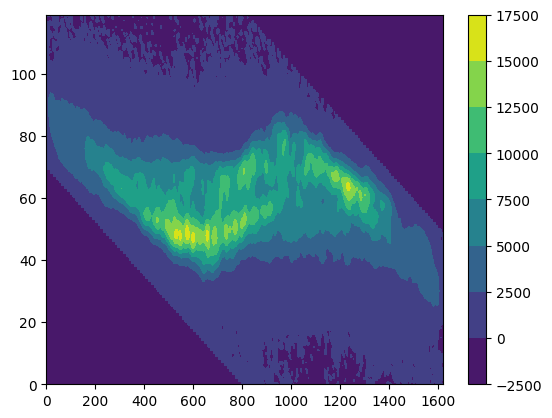

In [8]:
plt.contourf(np.nansum(rotated,axis=2))
plt.colorbar()

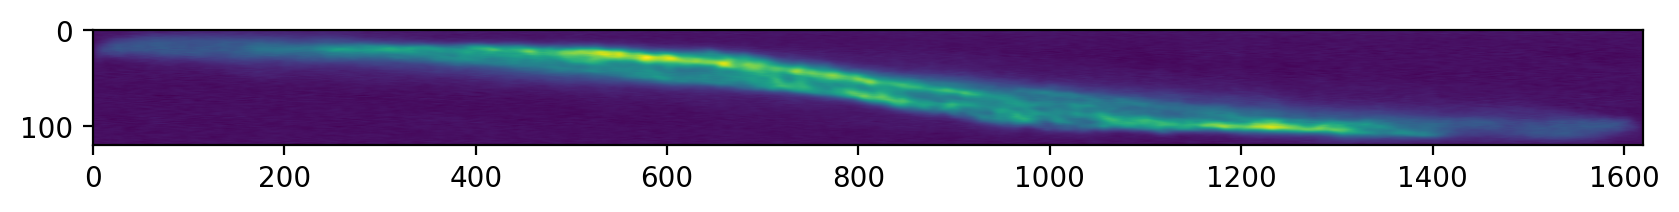

In [14]:
plt.figure(dpi=200,figsize=(10,10))

plt.imshow(np.nansum(m33_120pc,axis=2))
# plt.colorbar()
# plt.gca().set_aspect(5e-3)

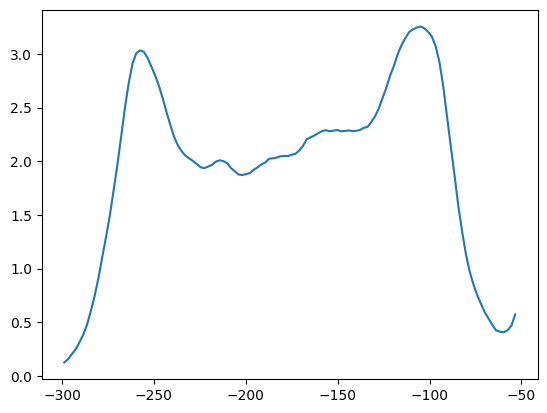

In [99]:
plt.plot(vax,np.nanmean(m33_120pc,axis=(1,2)))

In [15]:
m33_120pc.shape

(120, 1620, 1350)

In [21]:
plt.rcParams['font.size'] = 15

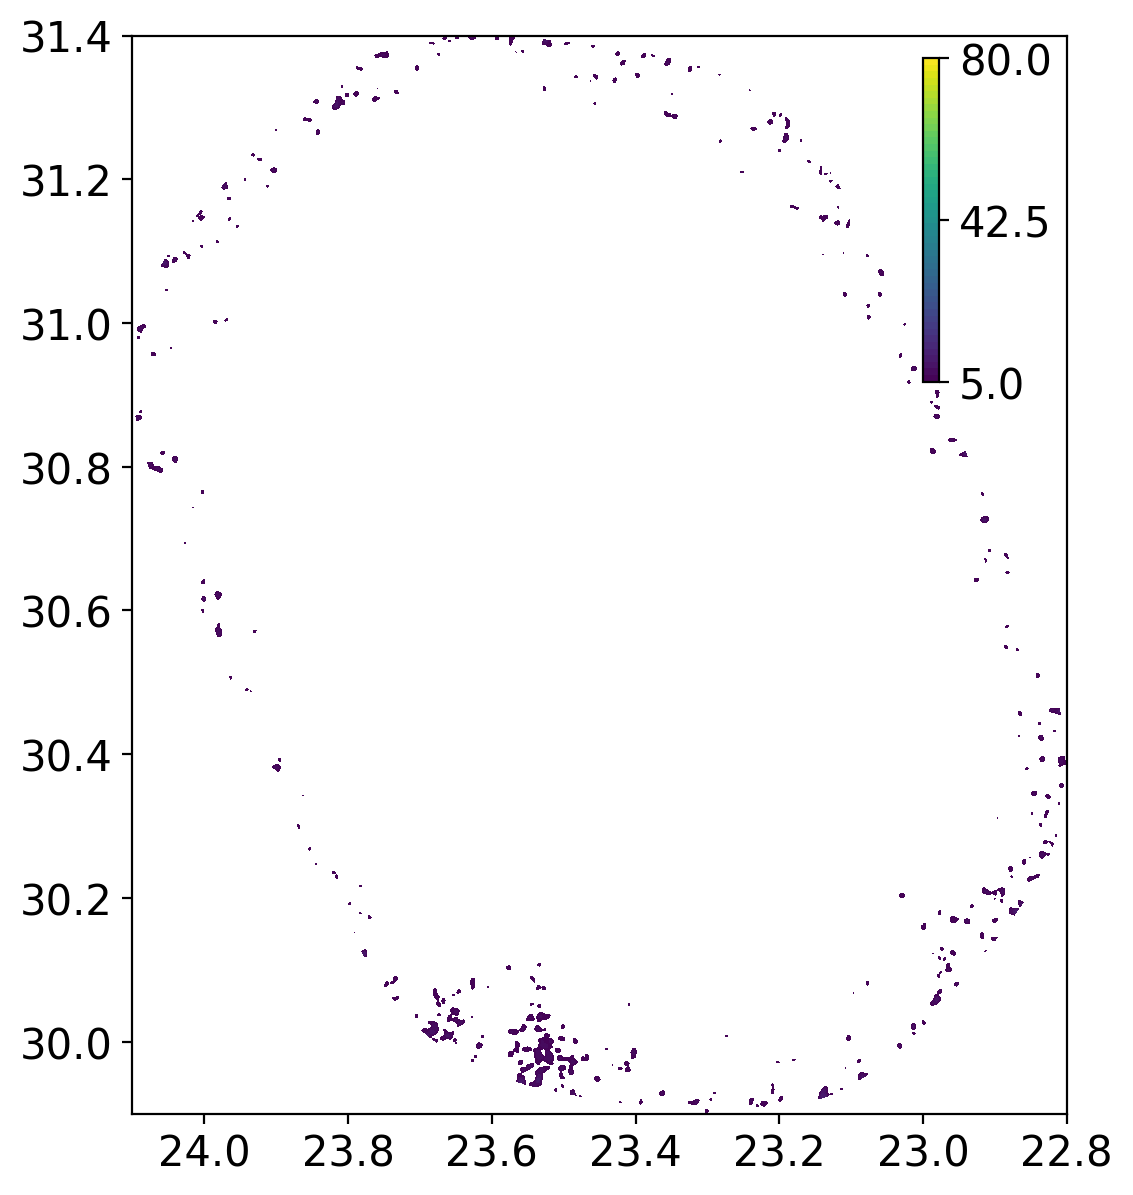

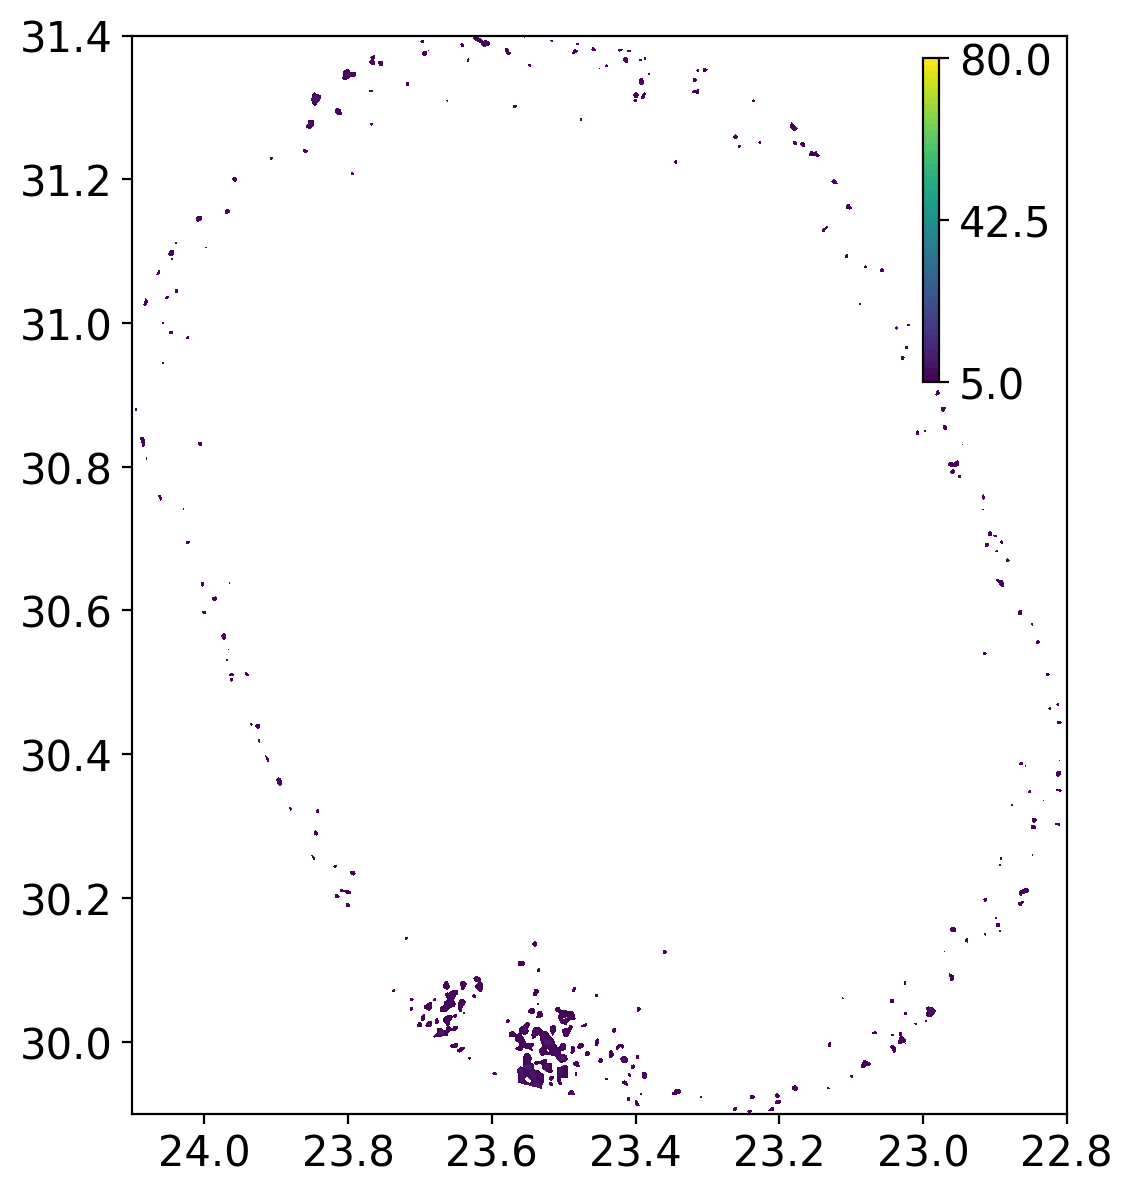

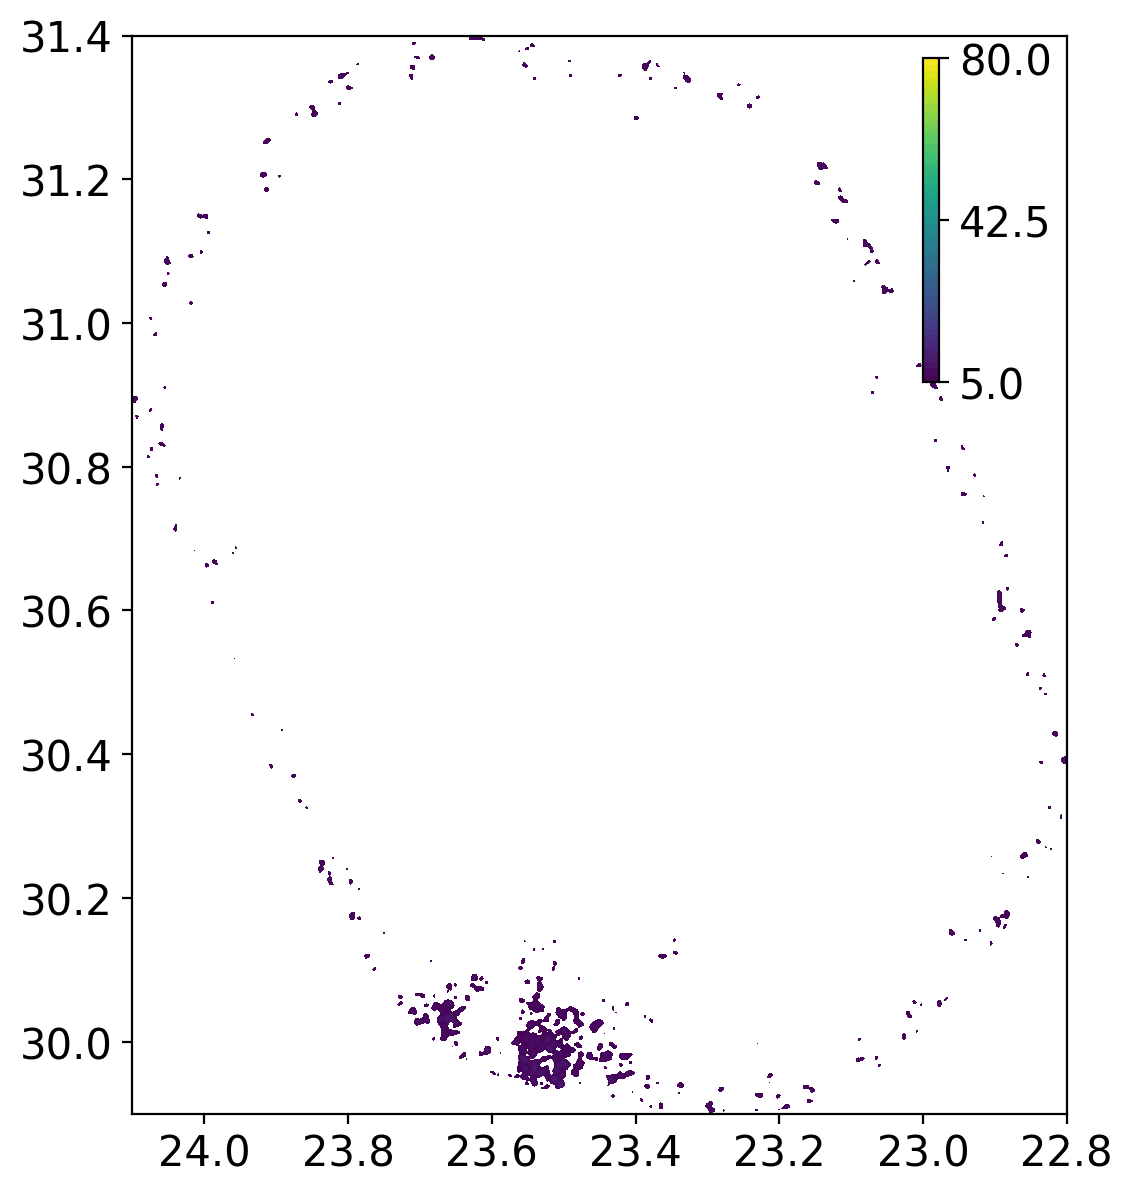

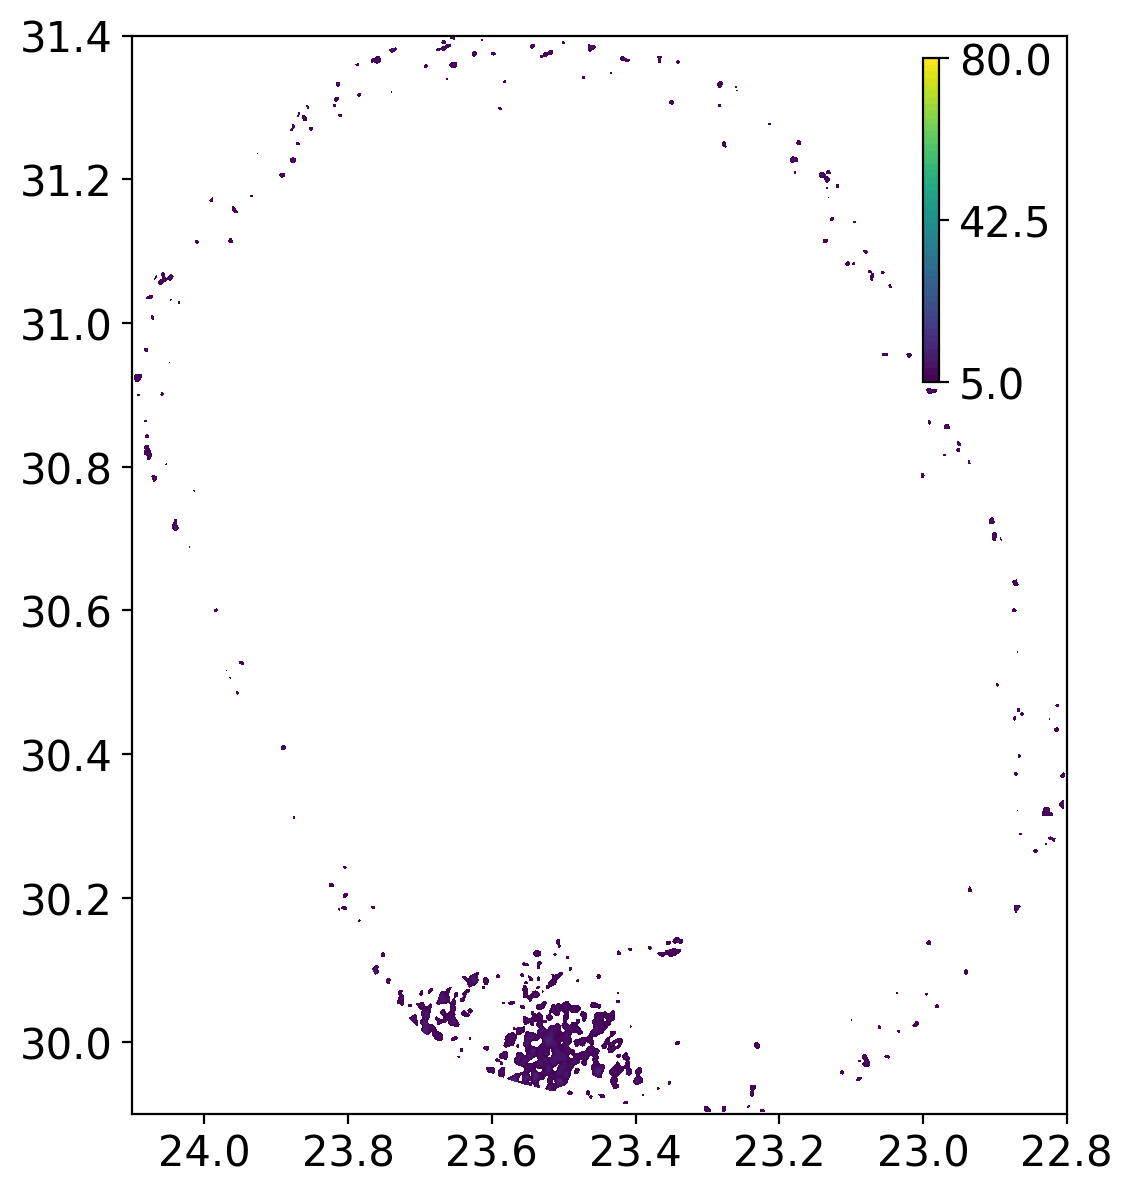

KeyboardInterrupt: 

In [32]:
for i in range(120):
    plt.figure(dpi=200,figsize=(12,7))
    plt.contourf(m33_120pc[i],levels=np.linspace(5,80),extent=[24.1,22.8,29.9,31.4])
    plt.gca().set_aspect(1)
    plt.xlim(24.1,22.8)
    plt.colorbar(shrink=0.3,anchor=(-0.9,0.97),ticks=np.linspace(5,80,3))
    plt.savefig(f'../data/v{i}.png',bbox_inches='tight')
    plt.show()
# plt.ylim(30,31.3)

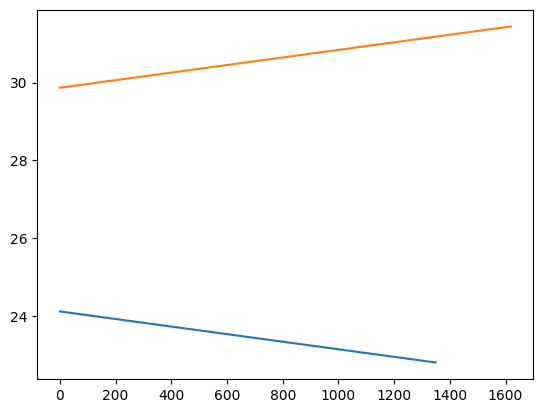

In [102]:
plt.plot(rax)
plt.plot(dax)
# plt.plot(vax)

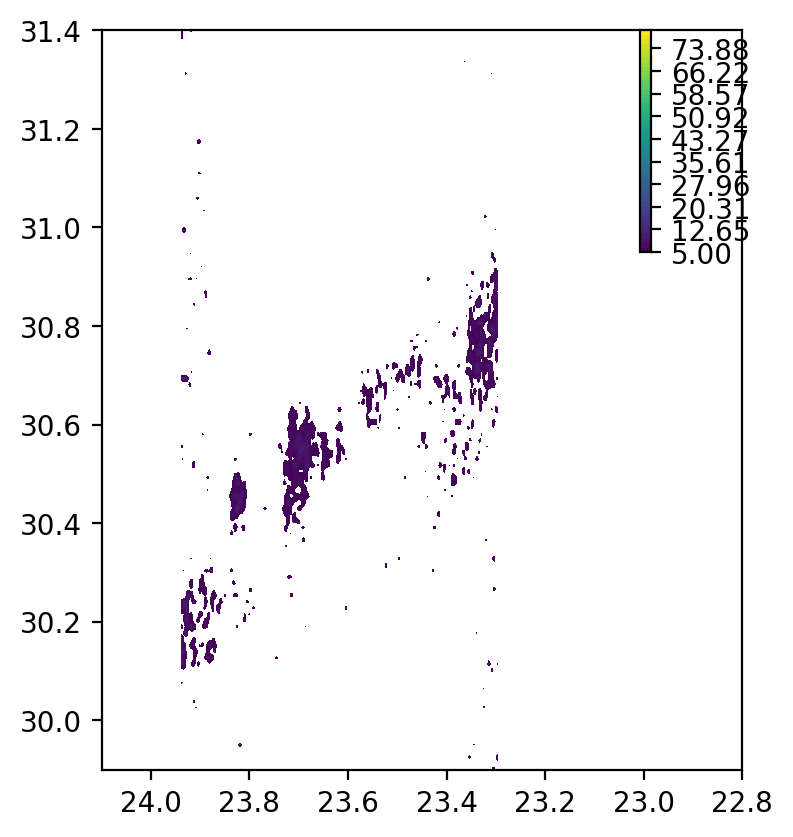

In [104]:
plt.figure(dpi=200)
plt.contourf(m33_120pc[:,:,1200],levels=np.linspace(5,80),extent=[24.1,22.8,29.9,31.4])
plt.gca().set_aspect(1)
plt.xlim(24.1,22.8)
plt.colorbar(shrink=0.3,anchor=(-1.1,1))#,ticks=5)
# plt.ylim(30,31.3)

(24.1, 22.8)

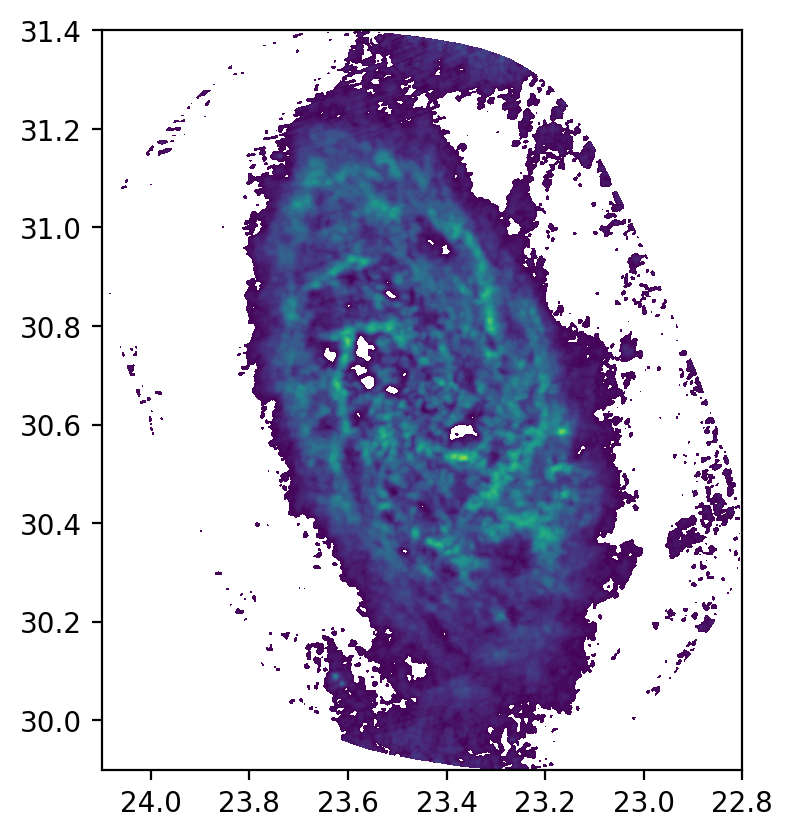

In [54]:
plt.figure(dpi=200)
plt.contourf(m0,levels=np.linspace(300,3000),extent=[24.1,22.8,29.9,31.4])
plt.gca().set_aspect(1)
plt.xlim(24.1,22.8)
# plt.ylim(30,31.3)

(24.1, 22.8)

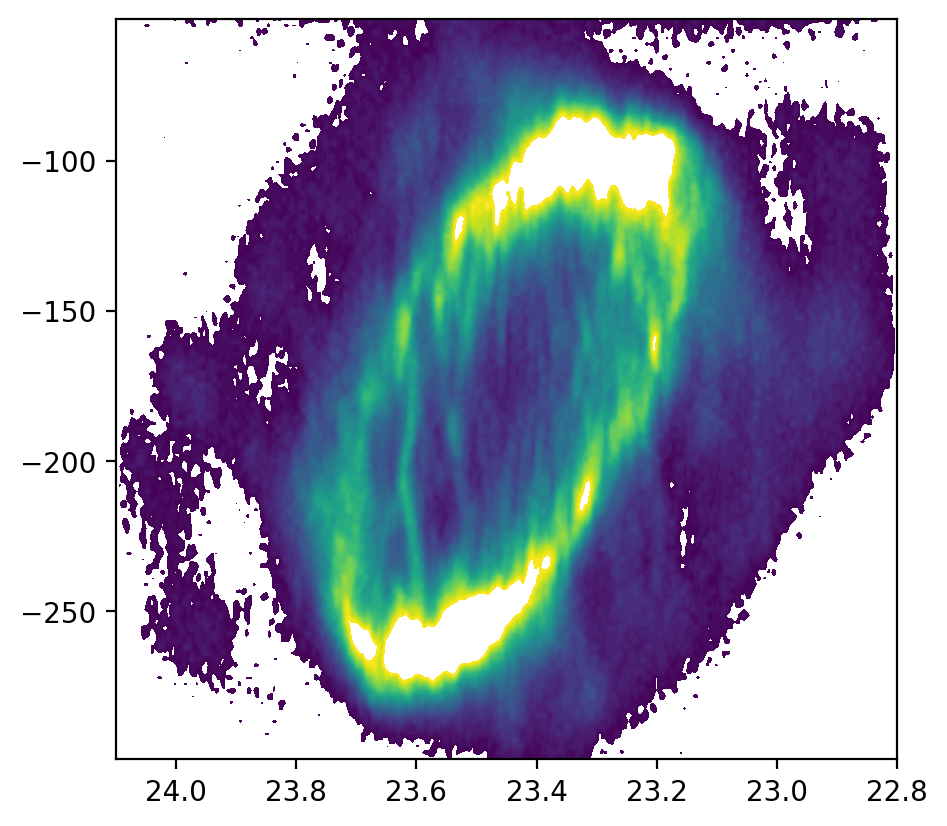

In [40]:
plt.figure(dpi=200)

plt.contourf(m0_lv,levels=np.linspace(500,10000),extent=[24.1,22.8,-53,-299])

plt.gca().set_aspect(5e-3)
plt.xlim(24.1,22.8)

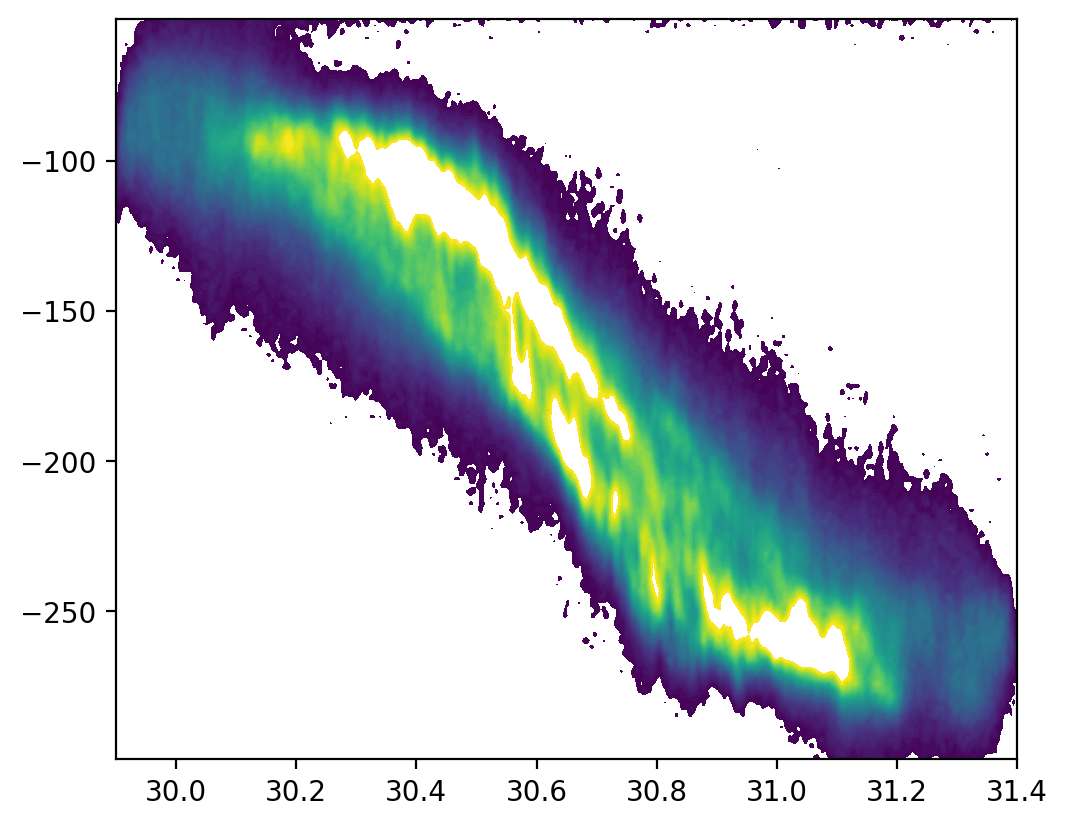

In [43]:
plt.figure(dpi=200)

plt.contourf(m0_bv,levels=np.linspace(500,10000),extent=[29.9,31.4,-53,-299])

plt.gca().set_aspect(5e-3)
# plt.xlim(24.1,22.8)

In [41]:
dax[[0,-1]]

array([29.86883333, 31.44286111])

In [13]:
rHI_pc = R_HI(ibb_tab1['M_GMC_1e4_Msun'].to_numpy()*1e4).to(u.pc).value
rHI_an = (rHI_pc/859000)*u.rad.to(u.deg)

In [7]:
header

SIMPLE  =                    T / conforms to FITS standard                      
BITPIX  =                  -32 / array data type                                
NAXIS   =                    3 / number of array dimensions                     
NAXIS1  =                 1350                                                  
NAXIS2  =                 1620                                                  
NAXIS3  =                  241                                                  
BTYPE   = 'Intensity'                                                           
OBJECT  = 'M33_1   '                                                            
BUNIT   = 'K       '           / Brightness (pixel) unit                        
ALTRVAL =   1.420072734544E+09 /Alternate frequency reference value             
ALTRPIX =   1.000000000000E+00 /Alternate frequency reference pixel             
VELREF  =                  257 /1 LSR, 2 HEL, 3 OBS, +256 Radio                 
COMMENT casacore non-standar

In [16]:
plt.rcParams['font.size'] = 20

In [17]:
plt.rcParams['font.family'] = 'STIXGeneral'
plt.rcParams['mathtext.fontset'] = 'stix' 

(30.0, 31.3)

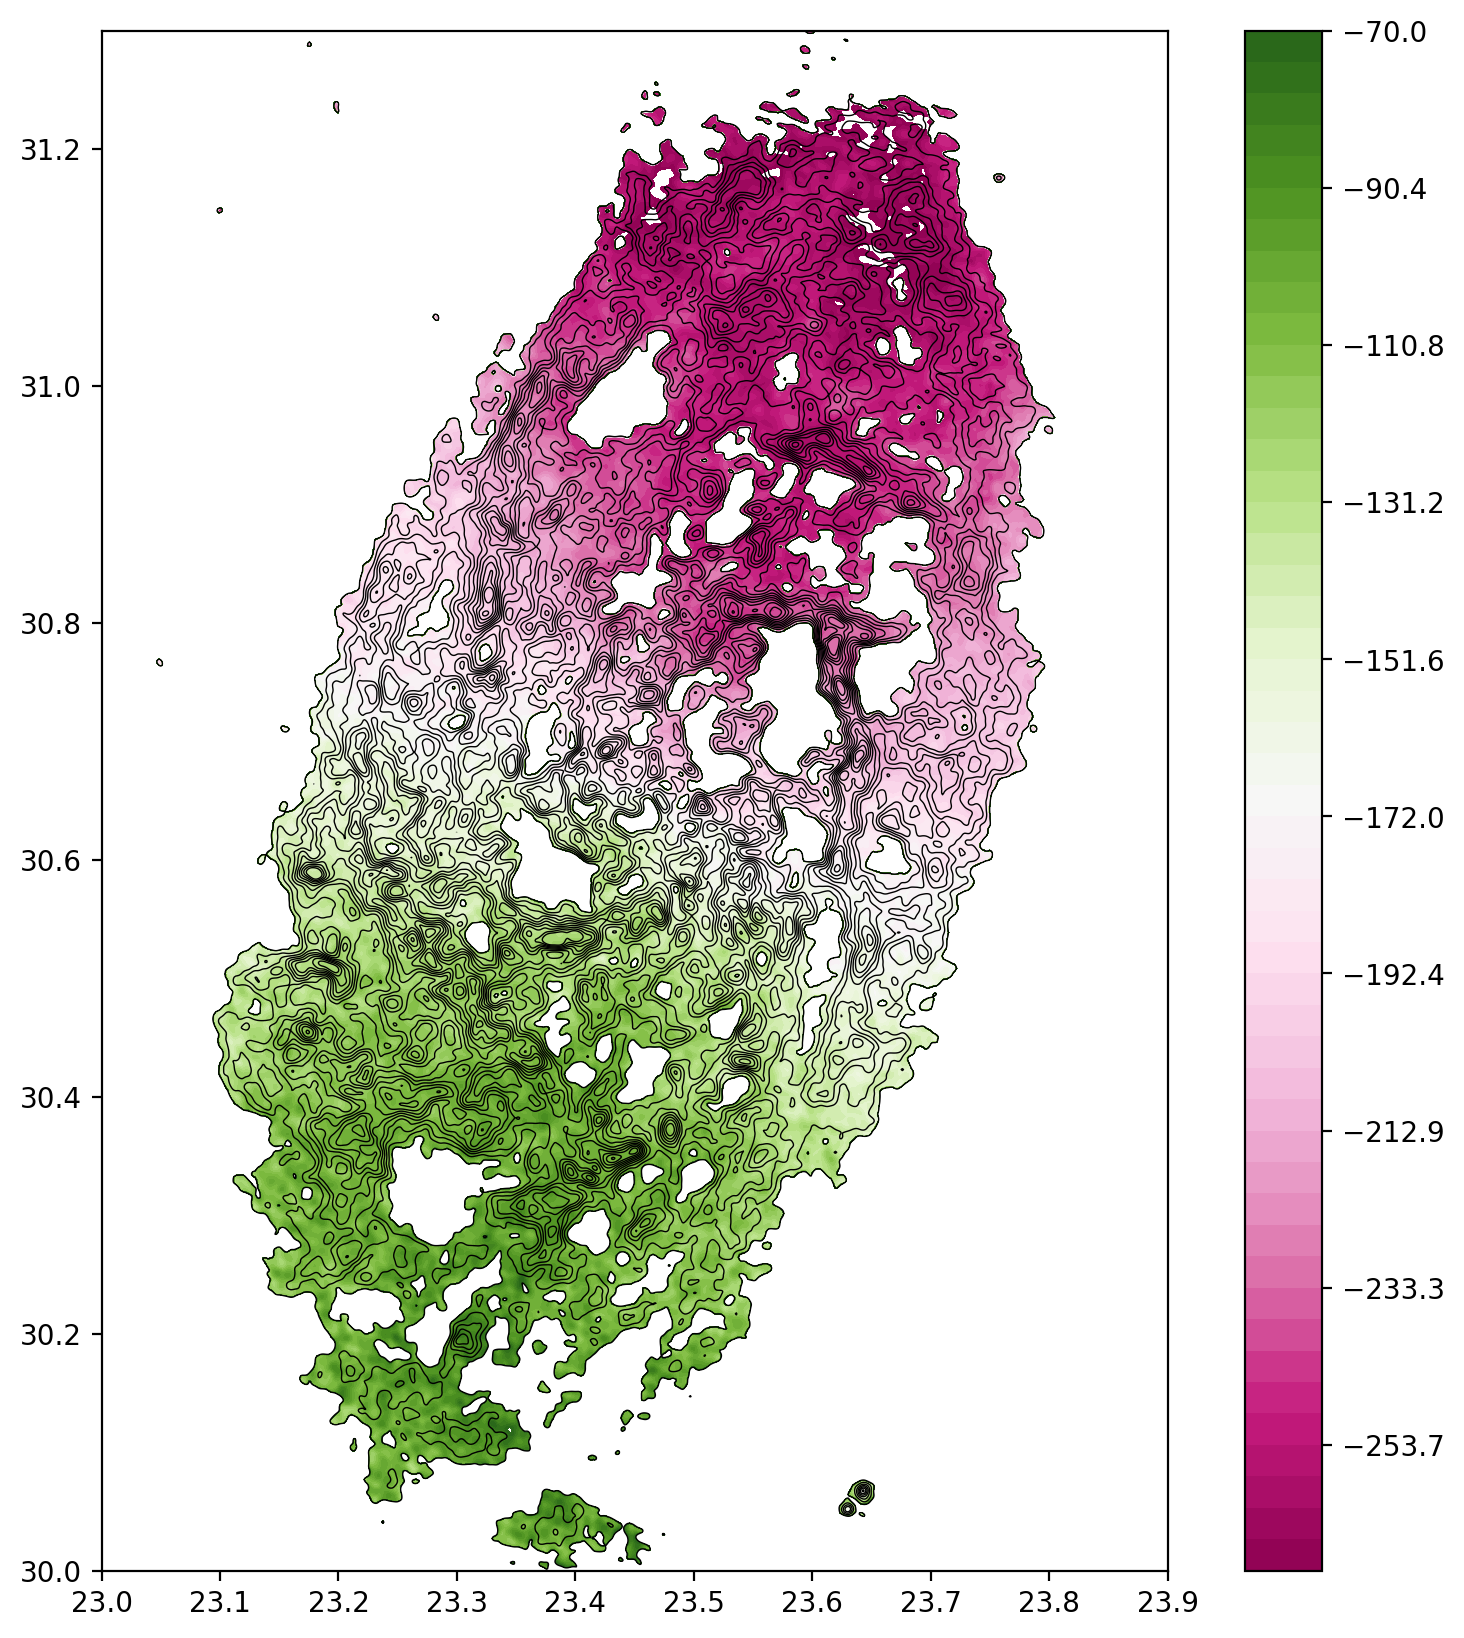

In [ ]:
plt.figure(dpi=200,figsize=(10,10))
plt.contourf(m1*(m0>300),extent=[rax[0],rax[-1],dax[0],dax[-1]],levels=np.linspace(-270,-70),cmap='PiYG')
plt.colorbar()

plt.contour(m0,extent=[rax[0],rax[-1],dax[0],dax[-1]],levels=np.linspace(300,1000,10),colors='black',linewidths=0.5)

plt.gca().set_aspect(1)

plt.xlim(23.,23.9)
plt.ylim(30.,31.3)

(30.0, 31.3)

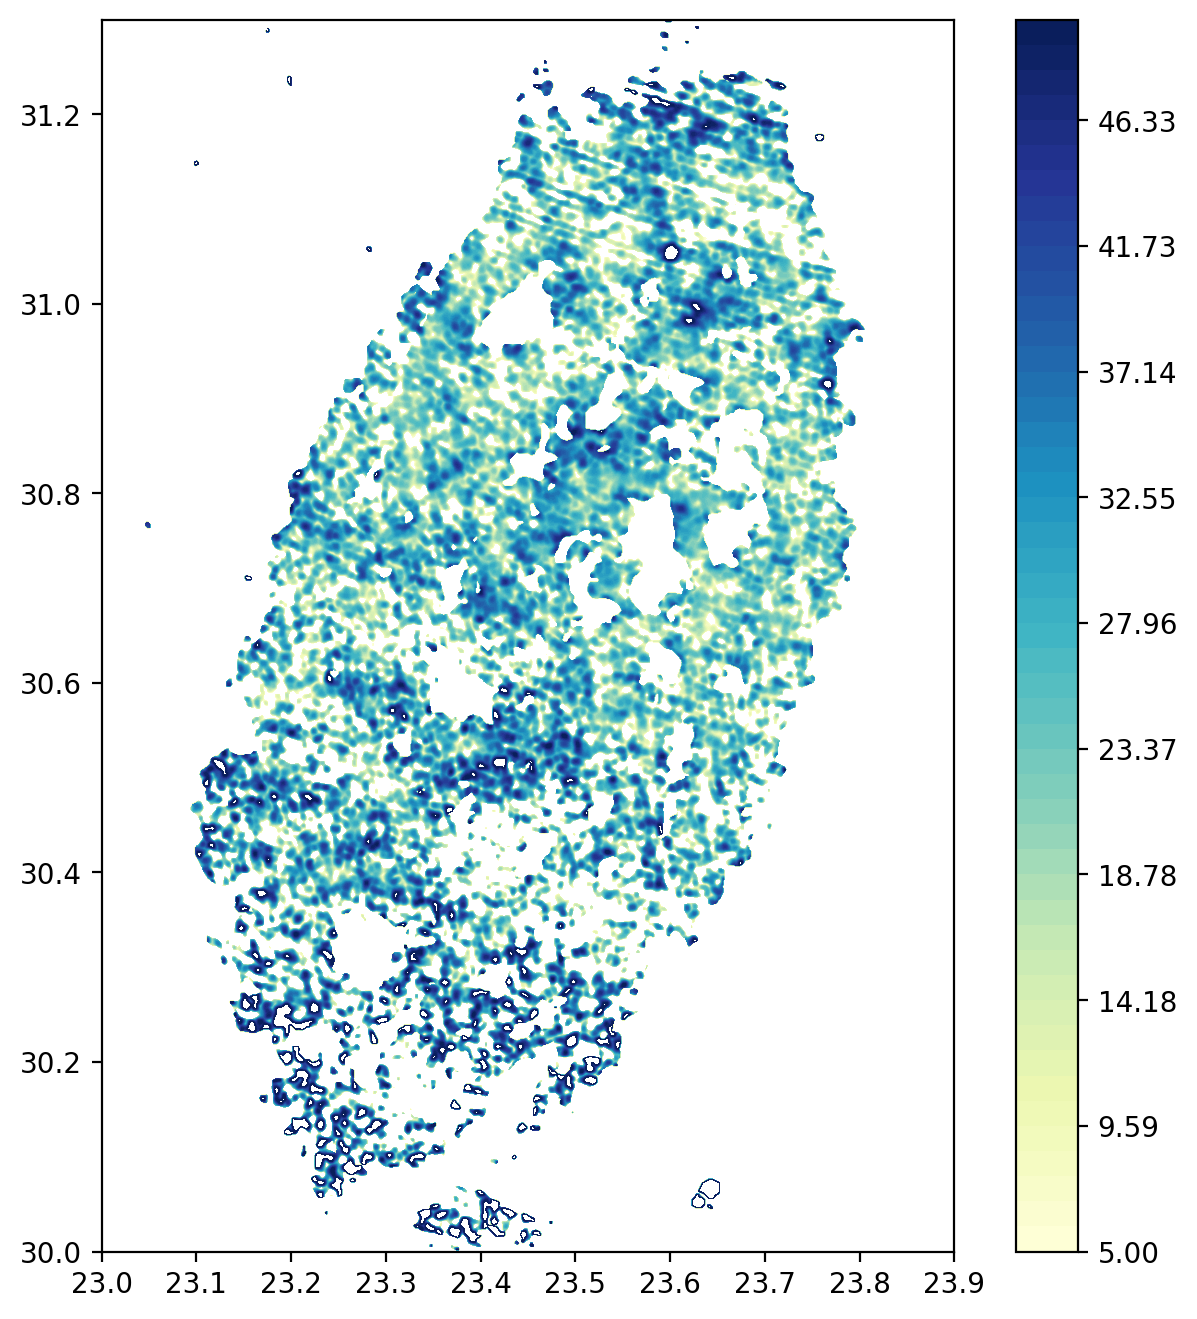

In [ ]:
plt.figure(dpi=200,figsize=(8,8))
plt.contourf(m2*(m0>300),extent=[rax[0],rax[-1],dax[0],dax[-1]],levels=np.linspace(5,50),cmap='YlGnBu')
plt.colorbar()
plt.gca().set_aspect(1)

plt.xlim(23.,23.9)
plt.ylim(30.,31.3)

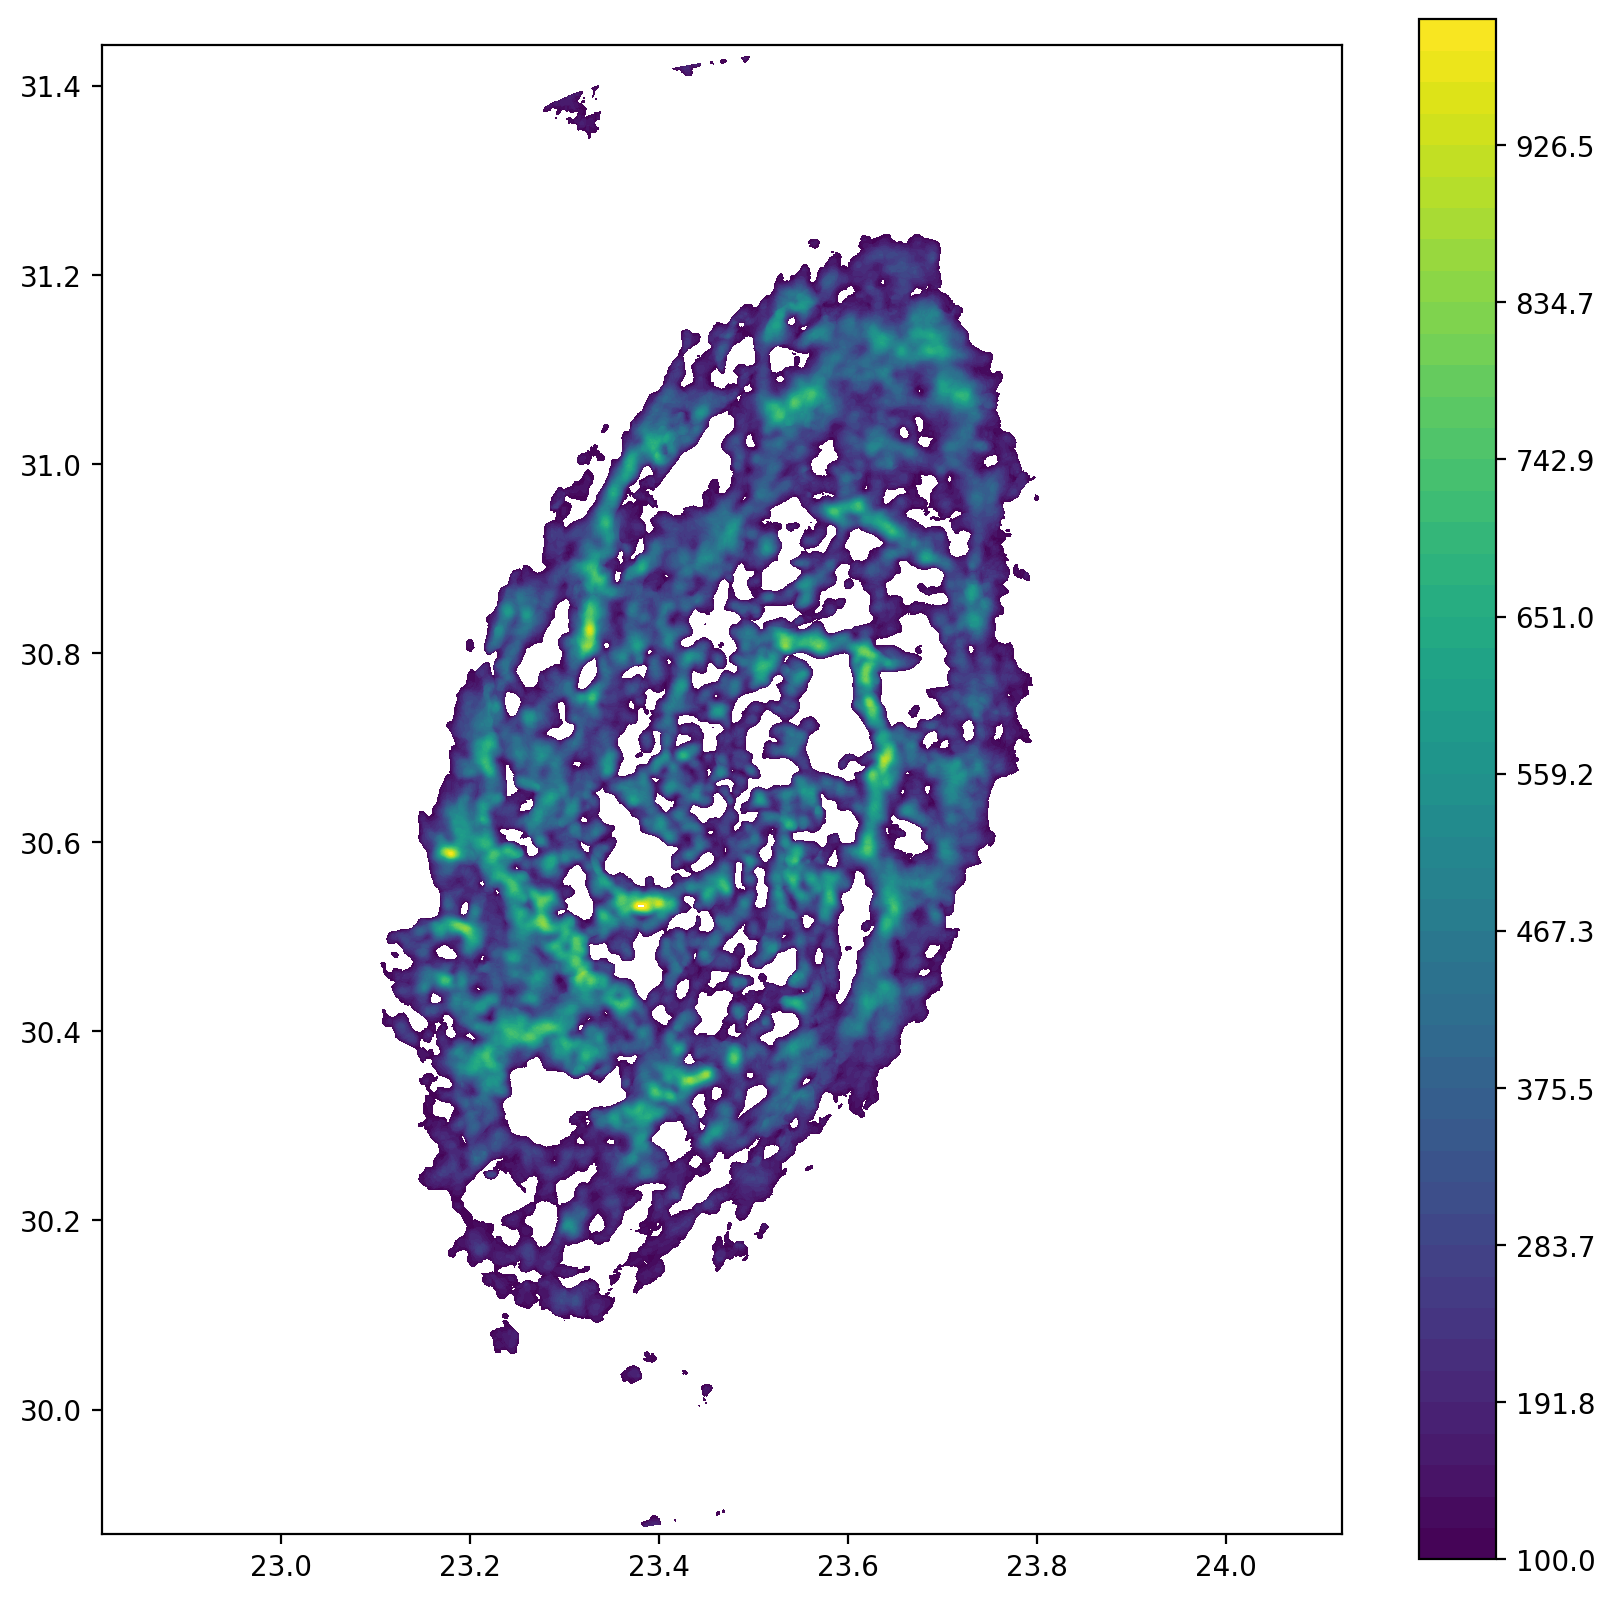

In [ ]:
plt.figure(dpi=200,figsize=(10,10))
plt.contourf(np.nansum(m33_120pc*(m33_120pc>20),axis=0),extent=[rax[0],rax[-1],dax[0],dax[-1]],levels=np.linspace(100,1000))
plt.colorbar()
plt.gca().set_aspect(1)

# plt.xlim(23.,23.9)
# plt.ylim(30.,31.3)